**Model Agreement Verification**

Loading ACCESS and MPI Datasets...
Processing ACCESS Model Outputs...
Processing MPI Model Outputs...

Generating Multi-Scenario Agreement Matrix Maps (12-Panel per Index)...
Saved Multi-Scenario Agreement Matrix: figures/MultiScenario_Agreement_Matrix_Precipitation.png


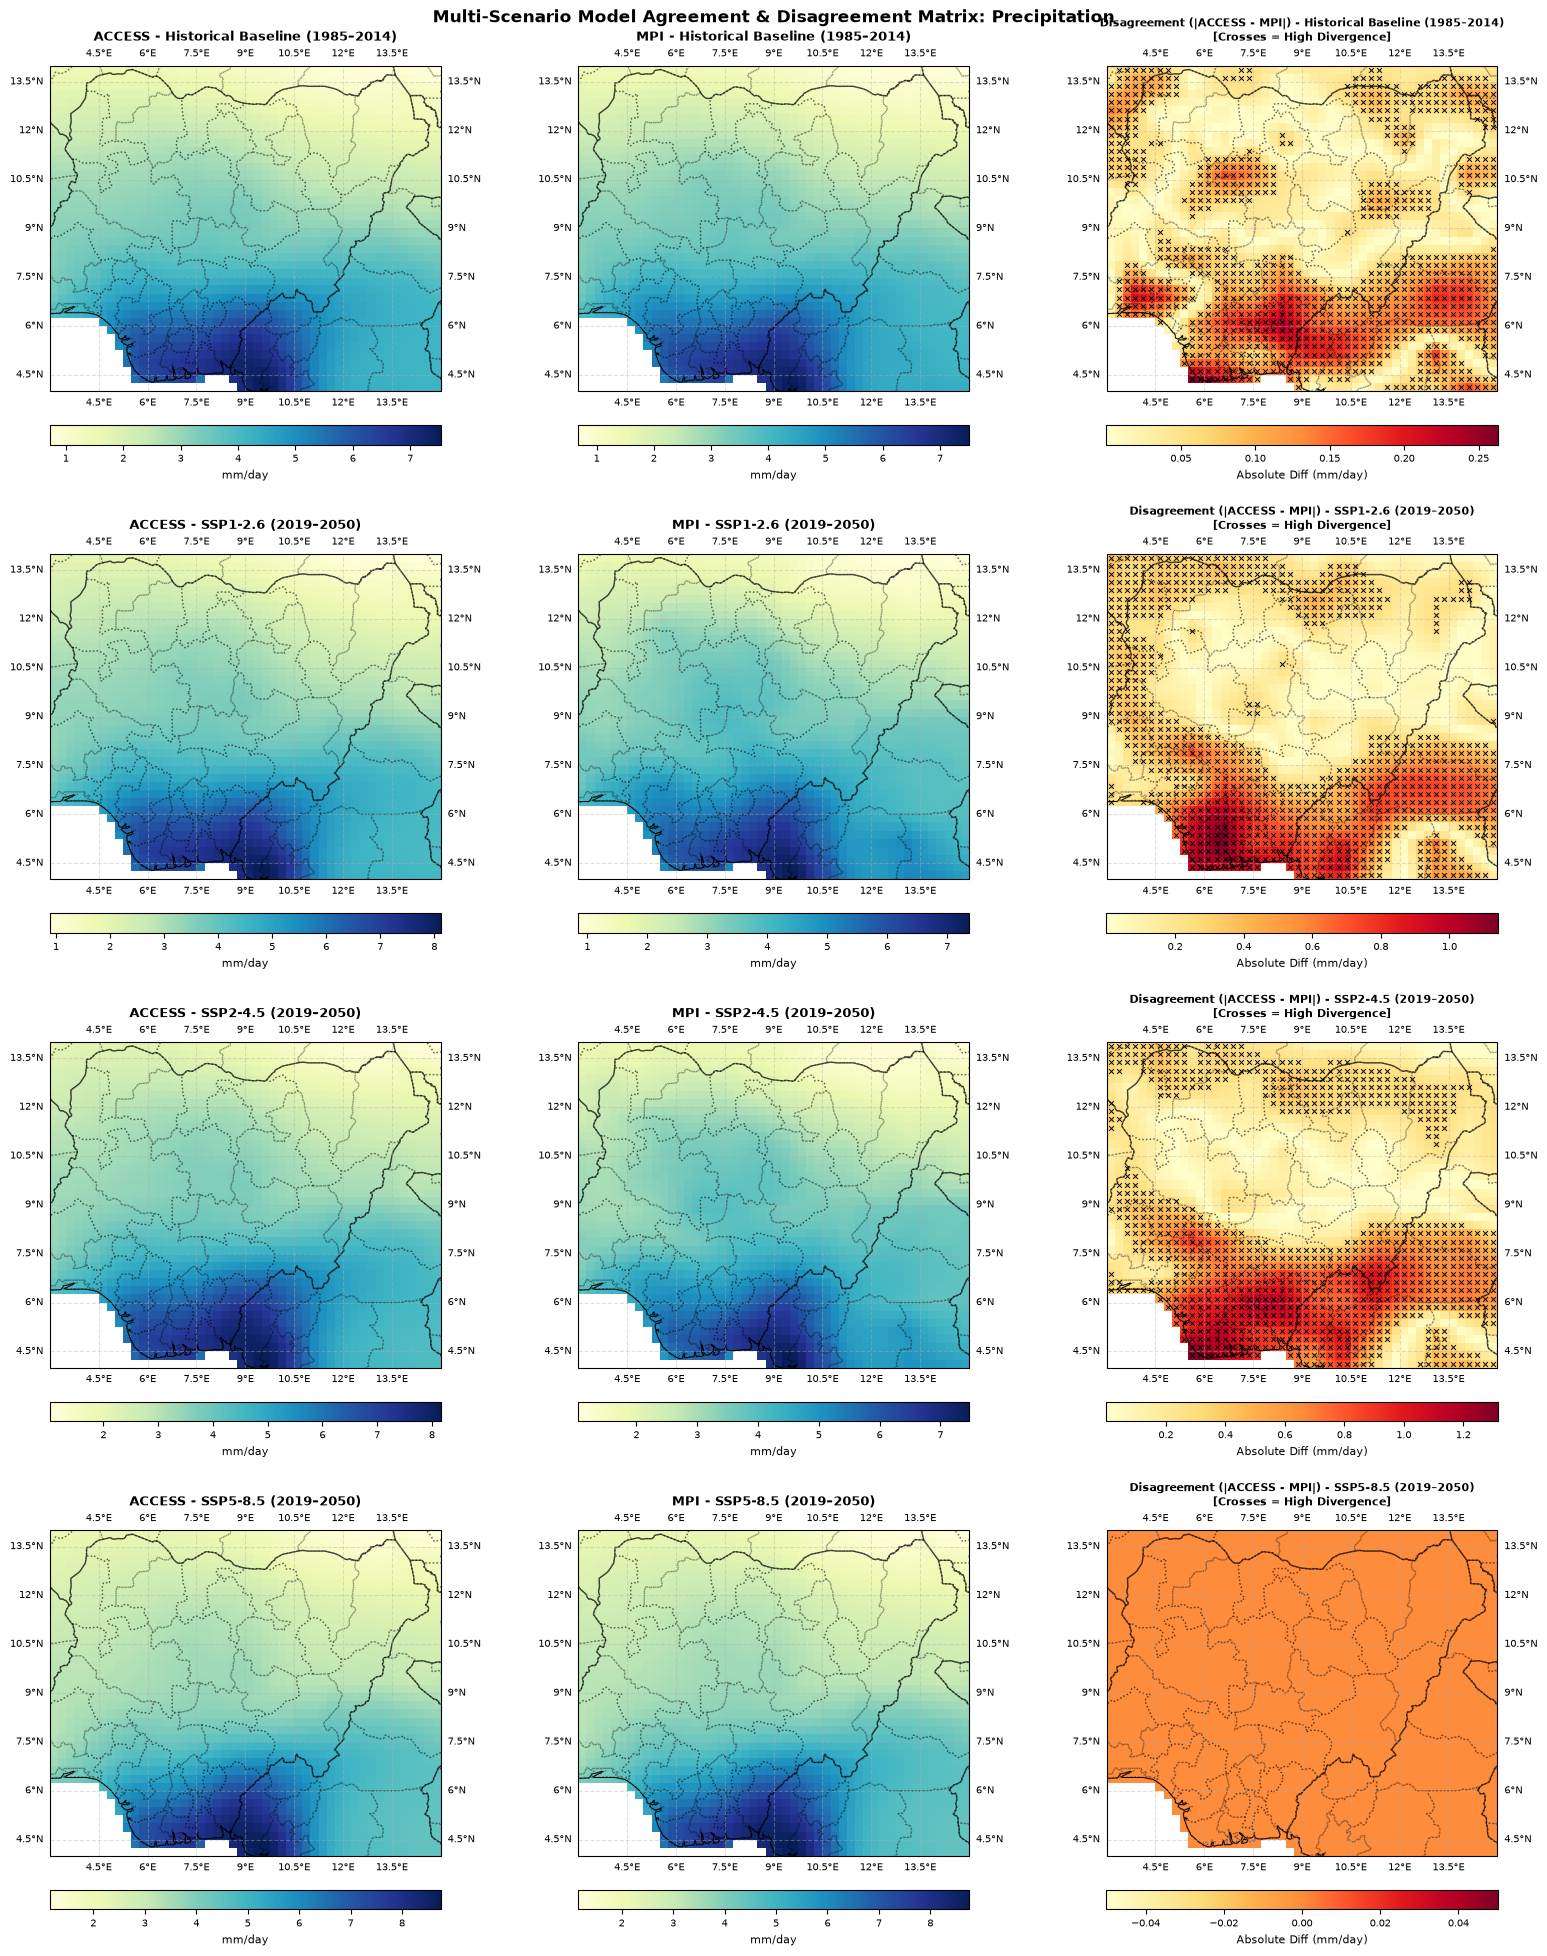

Saved Multi-Scenario Agreement Matrix: figures/MultiScenario_Agreement_Matrix_SDII.png


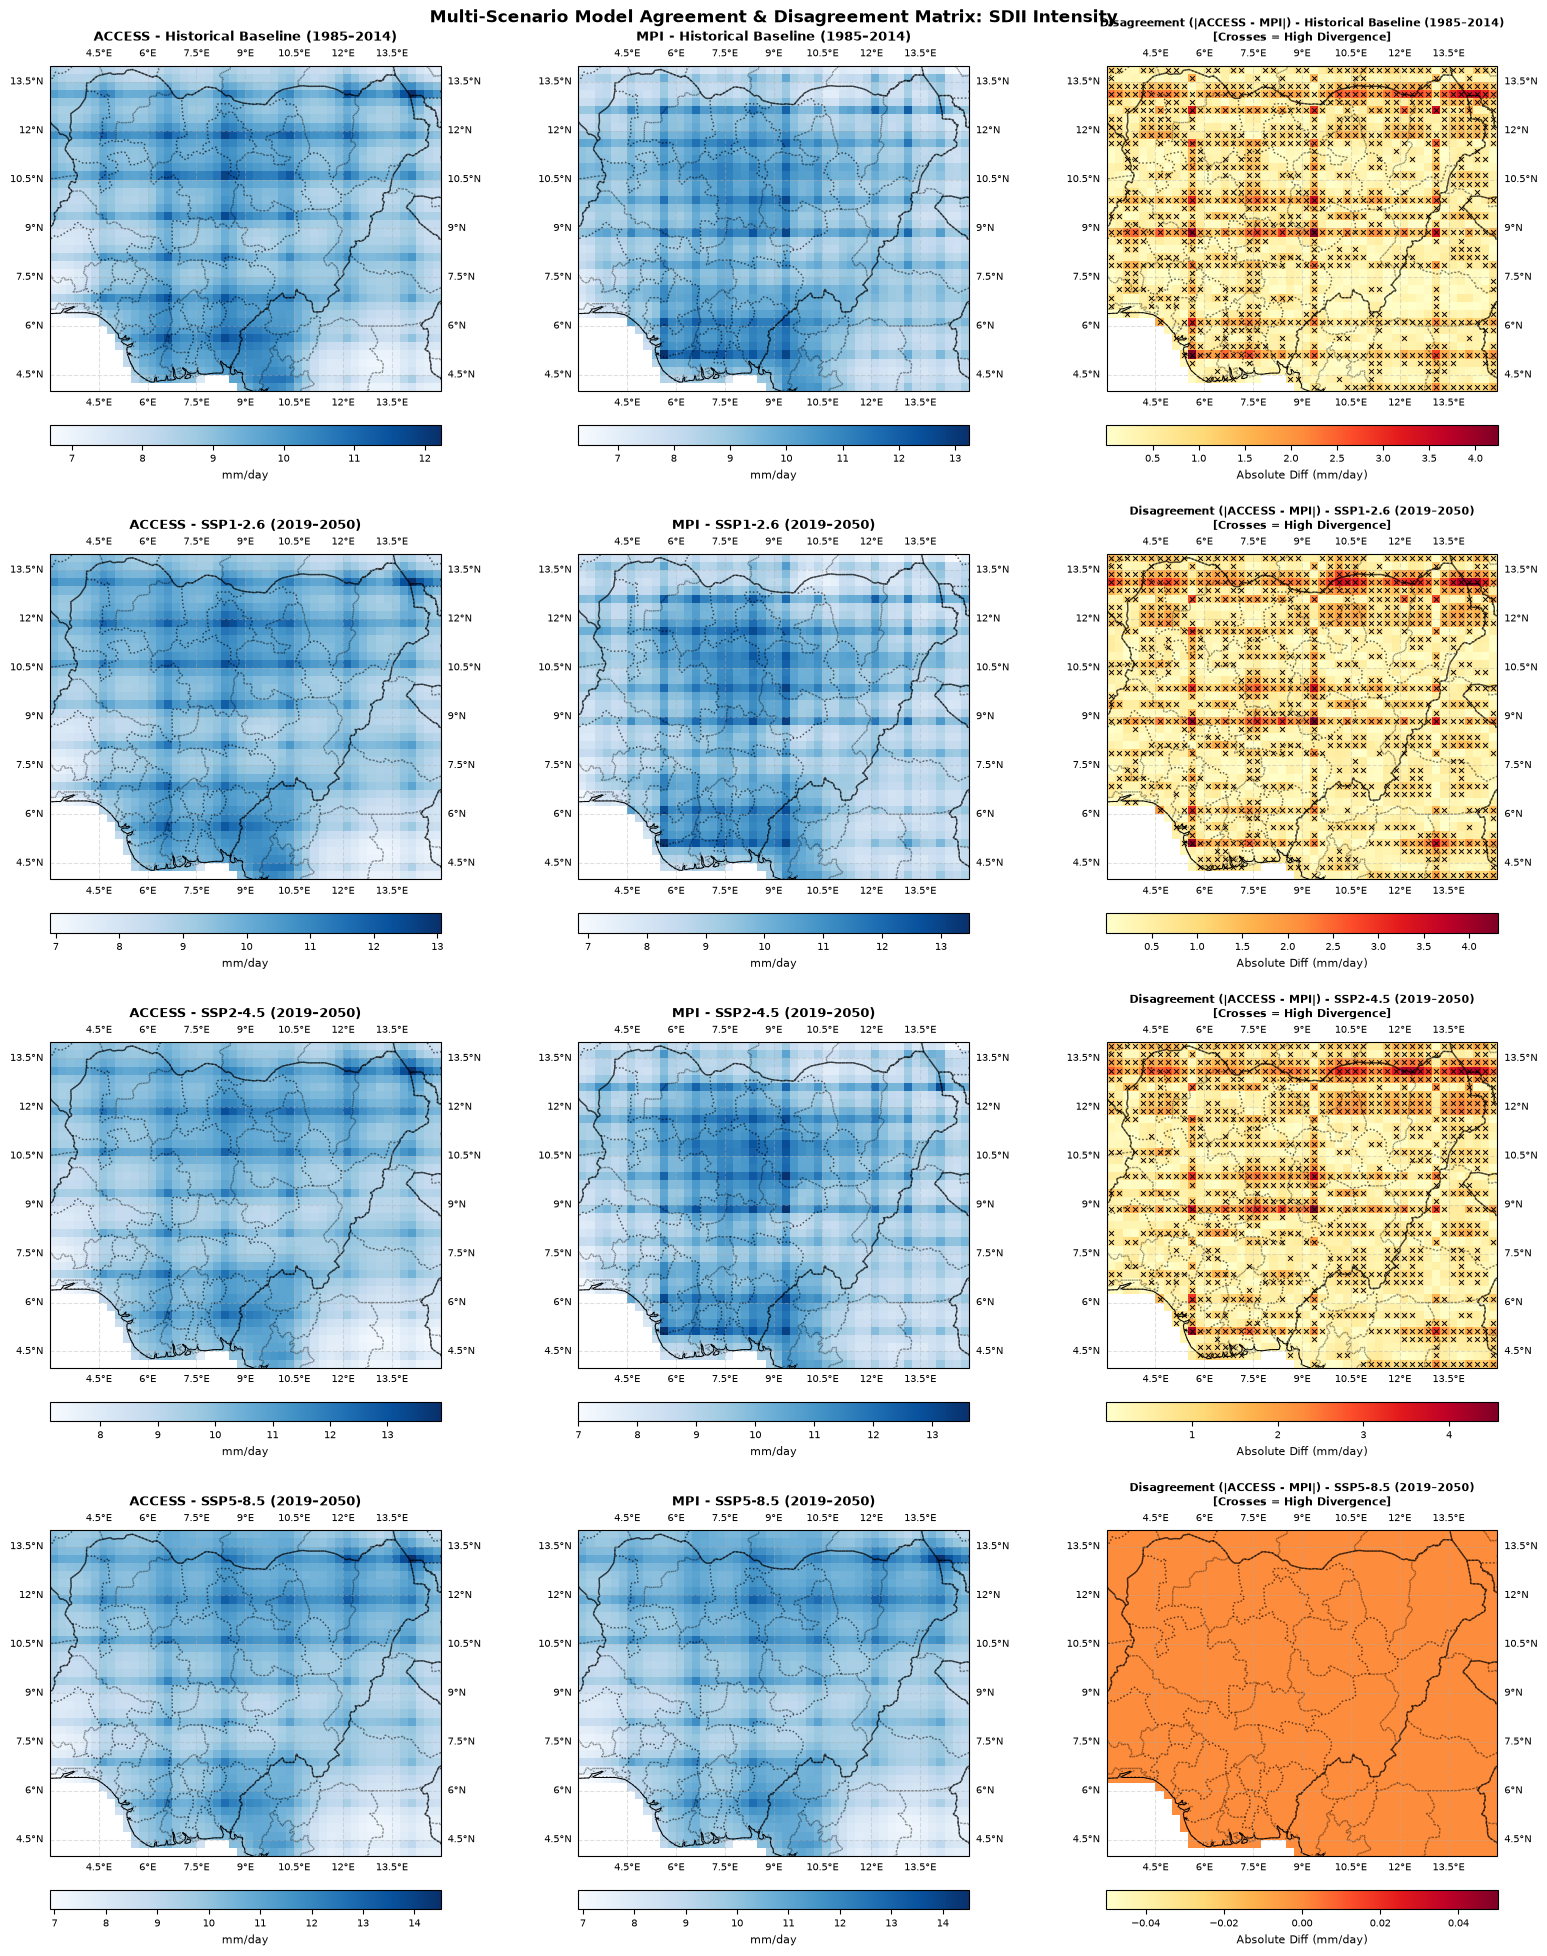

Saved Multi-Scenario Agreement Matrix: figures/MultiScenario_Agreement_Matrix_CWD.png


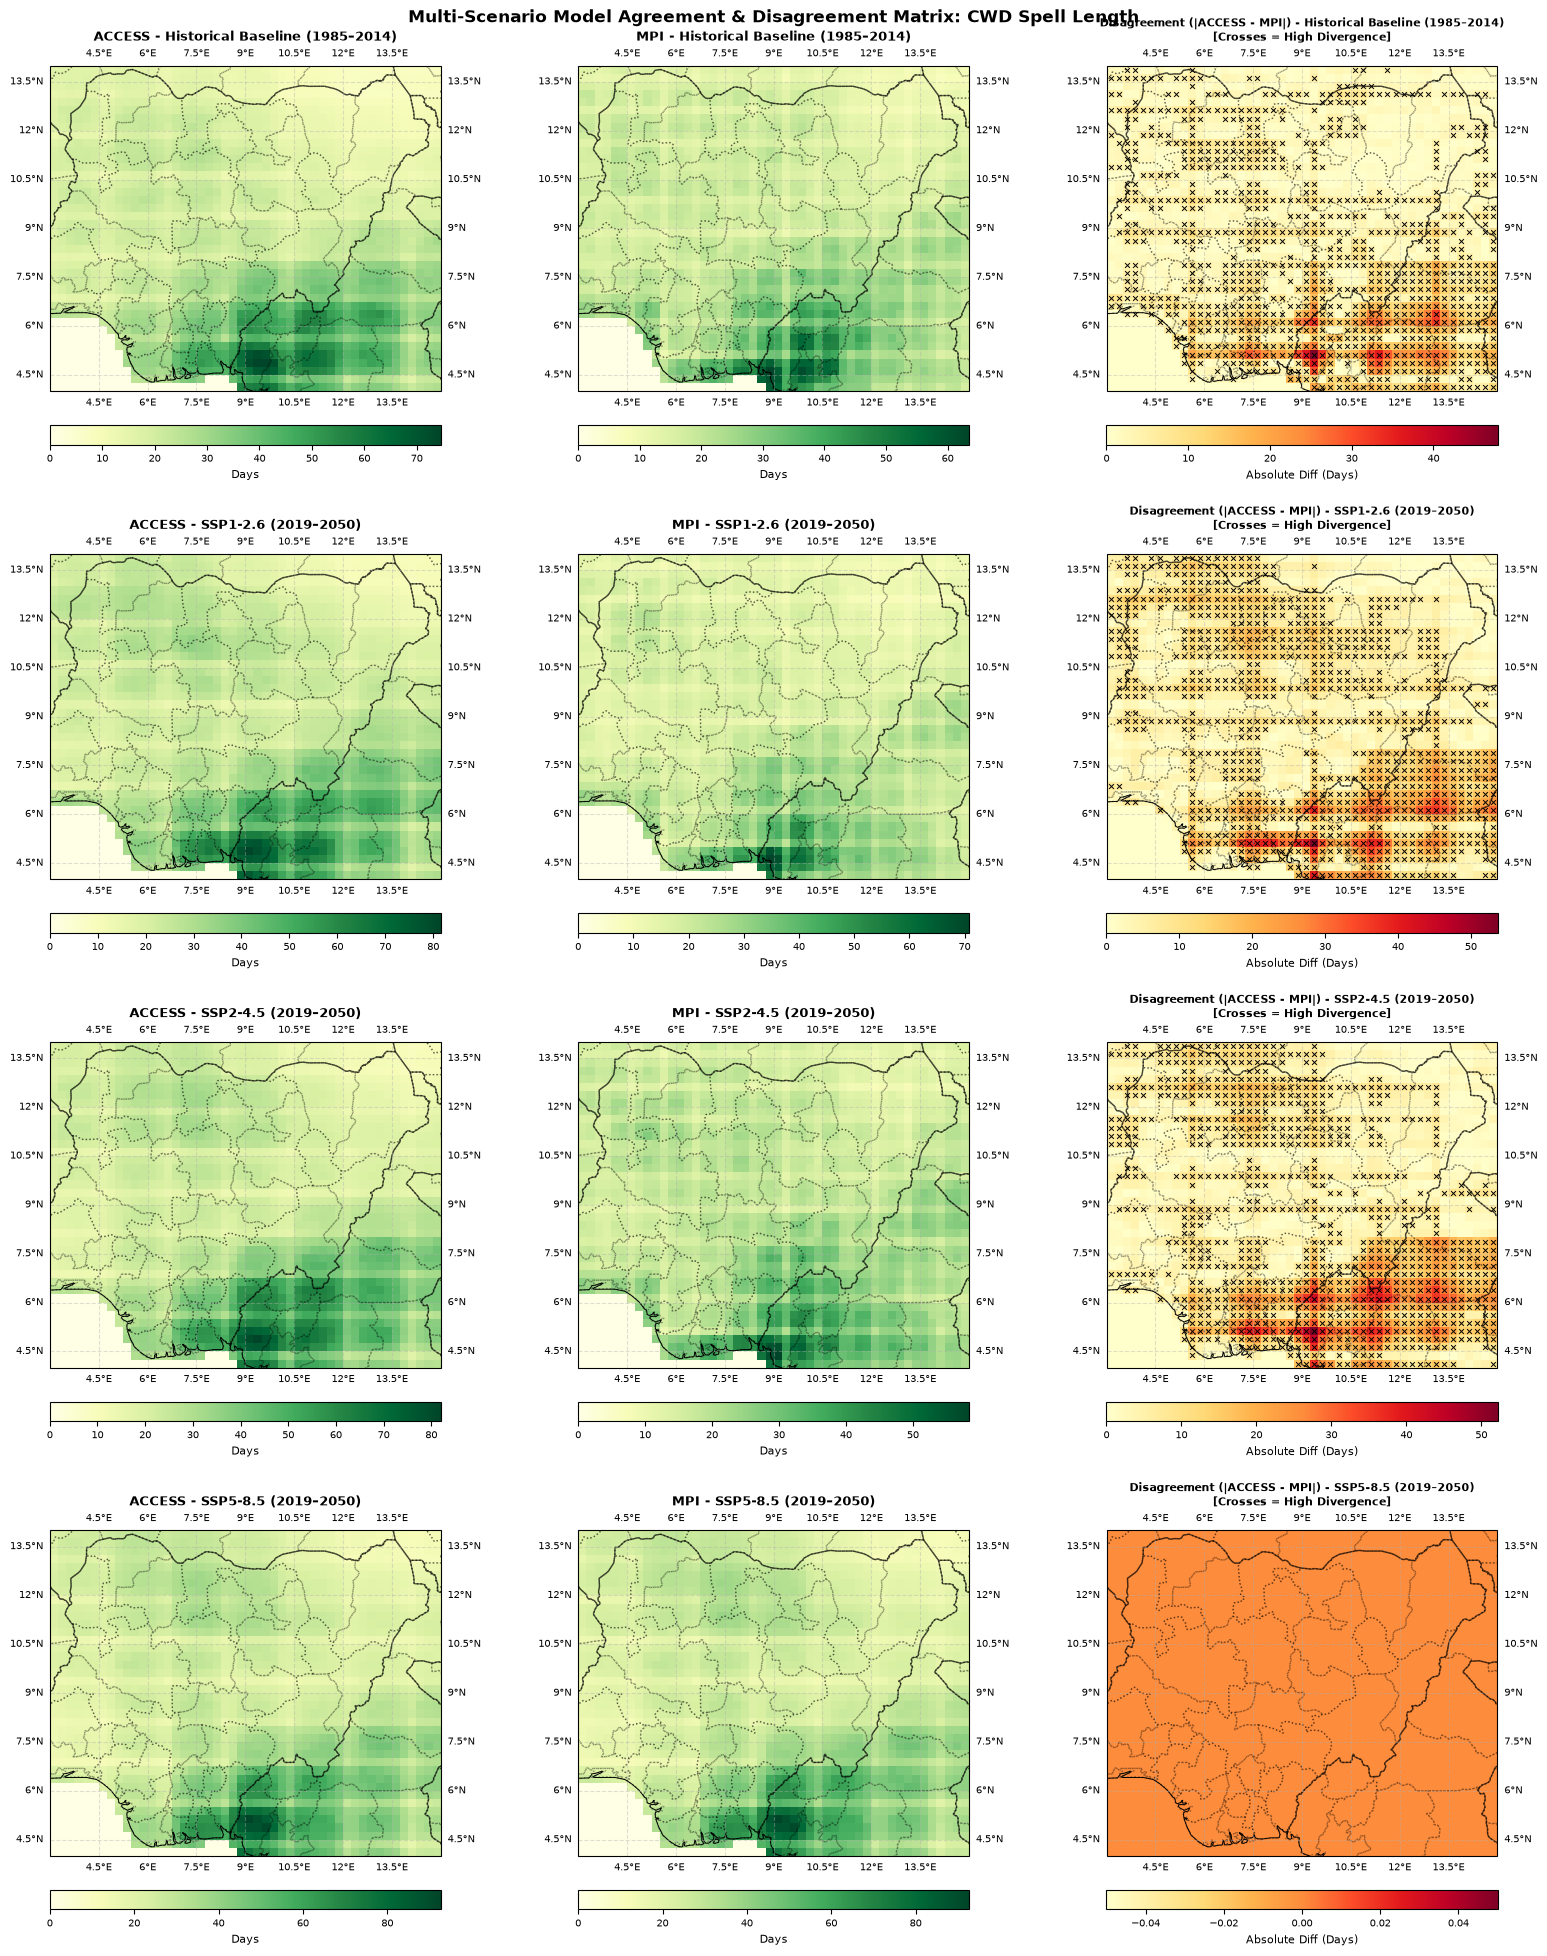


Generating Multi-Scenario Agreement Summary Tables...
Saved Agreement Table Image: figures/Model_Agreement_Table_Precipitation.png


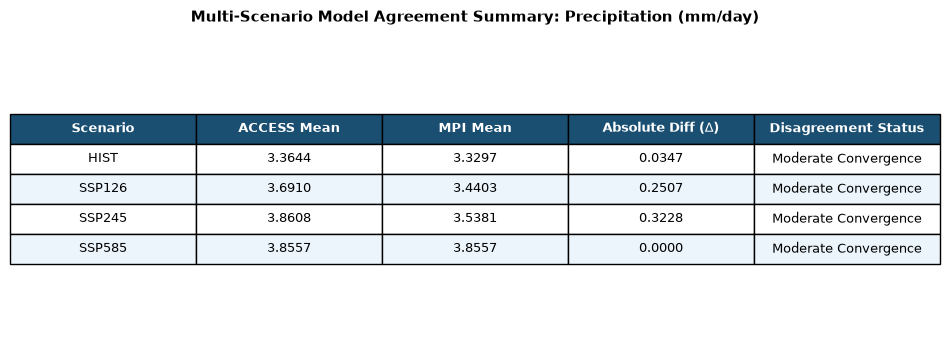

Saved Agreement Table Image: figures/Model_Agreement_Table_SDII.png


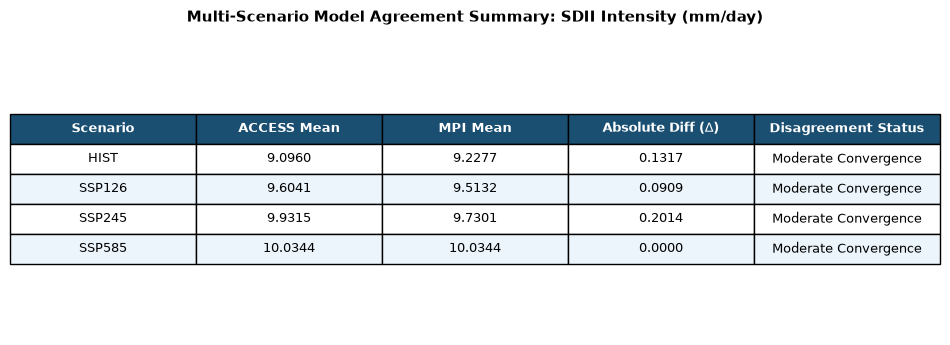

Saved Agreement Table Image: figures/Model_Agreement_Table_CWD.png


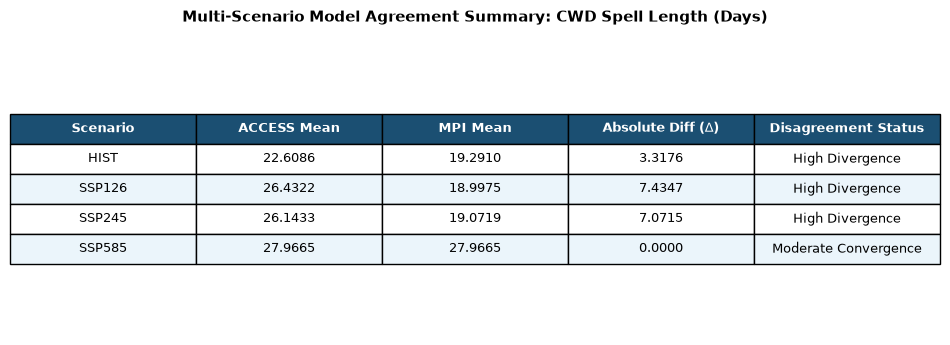


All multi-scenario agreement maps and tables successfully completed!


In [2]:
import warnings
warnings.filterwarnings('ignore')

import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os

# ==========================================
# 1. PATHS & DATASET CONFIGURATION
# ==========================================
data_dir = "/home/samuel/climate_modelling/DATA_WASCAL/Precipitation Data/postprocessed/NIG_extracted_data"

files_access = {
    'hist': "NIG_pr_ACCESS_historical.nc",
    'ssp126': "NIG_pr_ACCESS_ssp126.nc",
    'ssp245': "NIG_pr_ACCESS_ssp245.nc",
    'ssp585': "NIG_pr_ACCESS_ssp585.nc"
}

files_mpi = {
    'hist': "NIG_pr_MPI_historical.nc",
    'ssp126': "NIG_pr_MPI_ssp126.nc",
    'ssp245': "NIG_pr_MPI_ssp245.nc",
    'ssp585': "NIG_pr_MPI_ssp585"  # Exact filename without .nc
}

print("Loading ACCESS and MPI Datasets...")
ds_acc = {k: xr.open_dataset(os.path.join(data_dir, f)) for k, f in files_access.items()}
ds_mpi = {k: xr.open_dataset(os.path.join(data_dir, f)) for k, f in files_mpi.items()}

# Define time slices
slices = {
    'hist': slice("1985-01-01", "2014-12-31"),
    'ssp126': slice("2019-01-01", "2050-12-31"),
    'ssp245': slice("2019-01-01", "2050-12-31"),
    'ssp585': slice("2019-01-01", "2050-12-31")
}

# ==========================================
# 2. CORE CLIMATE INDICES FUNCTION
# ==========================================
def compute_indices(ds_slice):
    """Computes Mean Precipitation, SDII, and CWD for a given dataset slice."""
    pr = ds_slice['pr']
    mean_pr = pr.mean(dim='time')
    
    # Wet day mask (P >= 1.0 mm/day)
    wet_days = pr >= 1.0
    
    # SDII: Simple Daily Intensity Index
    ann_tot = pr.resample(time='YE').sum()
    ann_wet = wet_days.resample(time='YE').sum().where(lambda x: x > 0)
    sdii = (ann_tot / ann_wet).mean(dim='time')
    
    # CWD: Consecutive Wet Days
    years = np.unique(ds_slice['time.year'].values)
    cwd_list = []
    for yr in years:
        sub = (pr.sel(time=str(yr)) >= 1.0).values
        nt, nlat, nlon = sub.shape
        cwd_yr = np.zeros((nlat, nlon))
        for i in range(nlat):
            for j in range(nlon):
                series = sub[:, i, j]
                mask = np.concatenate(([False], series, [False]))
                idx = np.flatnonzero(mask[1:] != mask[:-1])
                if len(idx) > 0:
                    runs = idx[1::2] - idx[0::2]
                    cwd_yr[i, j] = np.max(runs) if len(runs) > 0 else 0
        cwd_list.append(xr.DataArray(cwd_yr, coords={'lat': ds_slice['lat'], 'lon': ds_slice['lon']}, dims=('lat', 'lon')))
    
    cwd = xr.concat(cwd_list, dim=pd.Index(years, name='year')).mean(dim='year')
    return mean_pr, sdii, cwd

print("Processing ACCESS Model Outputs...")
acc_res = {k: compute_indices(ds_acc[k].sel(time=slices[k])) for k in slices}

print("Processing MPI Model Outputs...")
mpi_res = {k: compute_indices(ds_mpi[k].sel(time=slices[k])) for k in slices}

# ==========================================
# 3. 12-PANEL MULTI-SCENARIO AGREEMENT MATRIX MAPPING FUNCTION
# ==========================================
def plot_multi_scenario_agreement_matrix(index_idx, title_prefix, cmap, filename, units):
    """
    Produces a 4x3 matrix figure:
    Rows: hist, ssp126, ssp245, ssp585
    Cols: ACCESS Model, MPI Model, Inter-Model Disagreement (with Crosses)
    """
    fig, axes = plt.subplots(4, 3, figsize=(16, 20), subplot_kw={'projection': ccrs.PlateCarree()})
    
    rows_meta = [
        ('hist', 'Historical Baseline (1985–2014)'),
        ('ssp126', 'SSP1-2.6 (2019–2050)'),
        ('ssp245', 'SSP2-4.5 (2019–2050)'),
        ('ssp585', 'SSP5-8.5 (2019–2050)')
    ]
    
    for r_idx, (scen_key, scen_label) in enumerate(rows_meta):
        acc_data = acc_res[scen_key][index_idx]
        mpi_data = mpi_res[scen_key][index_idx]
        
        # Column 1: ACCESS
        ax1 = axes[r_idx, 0]
        im1 = acc_data.plot(ax=ax1, transform=ccrs.PlateCarree(), cmap=cmap, add_colorbar=False)
        ax1.set_title(f"ACCESS - {scen_label}", fontsize=9, fontweight='bold')
        ax1.coastlines(resolution='50m', color='black', linewidth=0.7)
        ax1.add_feature(cfeature.BORDERS, linestyle='-', alpha=0.6)
        ax1.add_feature(cfeature.STATES, linestyle=':', alpha=0.4)
        gl1 = ax1.gridlines(draw_labels=True, linestyle='--', alpha=0.4)
        gl1.xlabel_style = {'size': 7}
        gl1.ylabel_style = {'size': 7}
        cbar1 = plt.colorbar(im1, ax=ax1, orientation='horizontal', pad=0.08, shrink=0.8)
        cbar1.set_label(units, fontsize=8)
        cbar1.ax.tick_params(labelsize=7)
        
        # Column 2: MPI
        ax2 = axes[r_idx, 1]
        im2 = mpi_data.plot(ax=ax2, transform=ccrs.PlateCarree(), cmap=cmap, add_colorbar=False)
        ax2.set_title(f"MPI - {scen_label}", fontsize=9, fontweight='bold')
        ax2.coastlines(resolution='50m', color='black', linewidth=0.7)
        ax2.add_feature(cfeature.BORDERS, linestyle='-', alpha=0.6)
        ax2.add_feature(cfeature.STATES, linestyle=':', alpha=0.4)
        gl2 = ax2.gridlines(draw_labels=True, linestyle='--', alpha=0.4)
        gl2.xlabel_style = {'size': 7}
        gl2.ylabel_style = {'size': 7}
        cbar2 = plt.colorbar(im2, ax=ax2, orientation='horizontal', pad=0.08, shrink=0.8)
        cbar2.set_label(units, fontsize=8)
        cbar2.ax.tick_params(labelsize=7)
        
        # Column 3: Inter-Model Disagreement & Crosses
        ax3 = axes[r_idx, 2]
        diff_data = abs(acc_data - mpi_data)
        disag_mask = diff_data > diff_data.median()
        
        im3 = diff_data.plot(ax=ax3, transform=ccrs.PlateCarree(), cmap='YlOrRd', add_colorbar=False)
        
        # Overlay Stippling Crosses ('x')
        lats = diff_data['lat'].values
        lons = diff_data['lon'].values
        lon2d, lat2d = np.meshgrid(lons, lats)
        ax3.scatter(lon2d[disag_mask.values], lat2d[disag_mask.values], 
                    transform=ccrs.PlateCarree(), color='black', marker='x', s=12, linewidths=0.7, label='High Disagreement')
        
        ax3.set_title(f"Disagreement (|ACCESS - MPI|) - {scen_label}\n[Crosses = High Divergence]", fontsize=8, fontweight='bold')
        ax3.coastlines(resolution='50m', color='black', linewidth=0.7)
        ax3.add_feature(cfeature.BORDERS, linestyle='-', alpha=0.6)
        ax3.add_feature(cfeature.STATES, linestyle=':', alpha=0.4)
        gl3 = ax3.gridlines(draw_labels=True, linestyle='--', alpha=0.4)
        gl3.xlabel_style = {'size': 7}
        gl3.ylabel_style = {'size': 7}
        cbar3 = plt.colorbar(im3, ax=ax3, orientation='horizontal', pad=0.08, shrink=0.8)
        cbar3.set_label(f"Absolute Diff ({units})", fontsize=8)
        cbar3.ax.tick_params(labelsize=7)
        
    plt.suptitle(f"Multi-Scenario Model Agreement & Disagreement Matrix: {title_prefix}", fontsize=12, fontweight='bold', y=0.98)
    plt.tight_layout()
    os.makedirs("figures", exist_ok=True)
    out_path = os.path.join("figures", filename)
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    print(f"Saved Multi-Scenario Agreement Matrix: {out_path}")
    plt.show()

print("\nGenerating Multi-Scenario Agreement Matrix Maps (12-Panel per Index)...")
plot_multi_scenario_agreement_matrix(0, "Precipitation", "YlGnBu", "MultiScenario_Agreement_Matrix_Precipitation.png", "mm/day")
plot_multi_scenario_agreement_matrix(1, "SDII Intensity", "Blues", "MultiScenario_Agreement_Matrix_SDII.png", "mm/day")
plot_multi_scenario_agreement_matrix(2, "CWD Spell Length", "YlGn", "MultiScenario_Agreement_Matrix_CWD.png", "Days")

# ==========================================
# 4. FUNCTION TO SAVE AGREEMENT TABLES AS IMAGES
# ==========================================
def save_table_image(data_rows, col_headers, title, filename):
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.axis('off')
    ax.axis('tight')
    
    table = ax.table(cellText=data_rows, 
                     colLabels=col_headers, 
                     loc='center', 
                     cellLoc='center')
    
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1.2, 1.8)
    
    for i in range(len(col_headers)):
        cell = table[(0, i)]
        cell.set_facecolor('#1b4f72')
        cell.set_text_props(color='white', weight='bold')
        
    for row_idx in range(1, len(data_rows) + 1):
        for col_idx in range(len(col_headers)):
            cell = table[(row_idx, col_idx)]
            if row_idx % 2 == 0:
                cell.set_facecolor('#ebf5fb')
            else:
                cell.set_facecolor('#ffffff')
                
    plt.title(title, fontsize=11, fontweight='bold', pad=15)
    
    os.makedirs("figures", exist_ok=True)
    out_path = os.path.join("figures", filename)
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    print(f"Saved Agreement Table Image: {out_path}")
    plt.show()

# Build multi-scenario agreement table data across all scenarios
headers = ['Scenario', 'ACCESS Mean', 'MPI Mean', 'Absolute Diff ($\Delta$)', 'Disagreement Status']

def get_scenario_rows(index_idx):
    rows = []
    for k in ['hist', 'ssp126', 'ssp245', 'ssp585']:
        acc_mean = float(acc_res[k][index_idx].mean().values)
        mpi_mean = float(mpi_res[k][index_idx].mean().values)
        diff_mean = abs(acc_mean - mpi_mean)
        status = 'Moderate Convergence' if diff_mean < 1.0 else 'High Divergence'
        rows.append([k.upper(), f"{acc_mean:.4f}", f"{mpi_mean:.4f}", f"{diff_mean:.4f}", status])
    return rows

print("\nGenerating Multi-Scenario Agreement Summary Tables...")
save_table_image(get_scenario_rows(0), headers, "Multi-Scenario Model Agreement Summary: Precipitation (mm/day)", "Model_Agreement_Table_Precipitation.png")
save_table_image(get_scenario_rows(1), headers, "Multi-Scenario Model Agreement Summary: SDII Intensity (mm/day)", "Model_Agreement_Table_SDII.png")
save_table_image(get_scenario_rows(2), headers, "Multi-Scenario Model Agreement Summary: CWD Spell Length (Days)", "Model_Agreement_Table_CWD.png")

print("\nAll multi-scenario agreement maps and tables successfully completed!")

Saved Unified Agreement Tables Image: figures/MultiScenario_Agreement_Tables_Unified.png


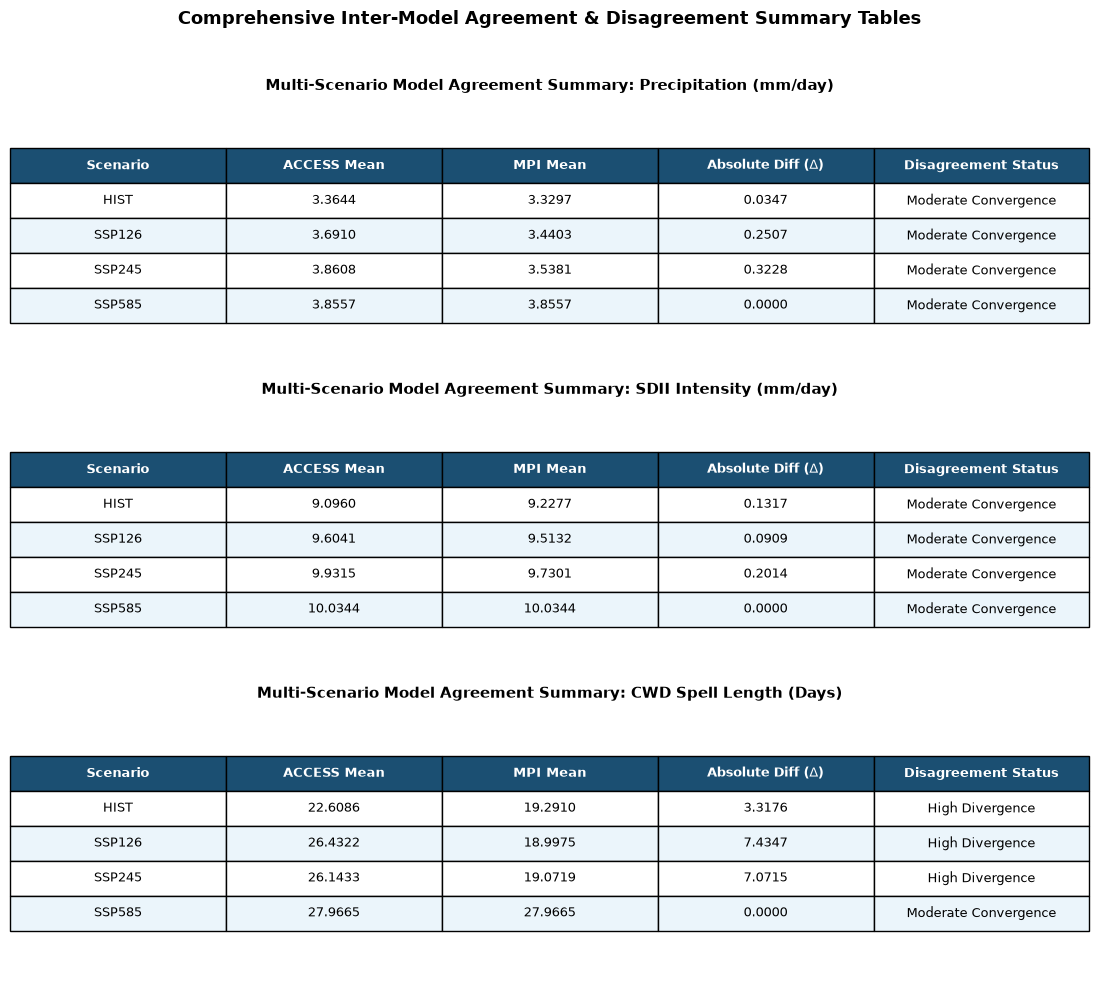

In [4]:
import matplotlib.pyplot as plt
import os

# ==========================================
# FUNCTION TO SAVE MULTI-TABLE IN A SINGLE PANE
# ==========================================
def save_unified_agreement_tables_image(pr_rows, sdii_rows, cwd_rows, col_headers, filename):
    fig, axes = plt.subplots(3, 1, figsize=(11, 10))
    
    tables_data = [
        ("Multi-Scenario Model Agreement Summary: Precipitation (mm/day)", pr_rows),
        ("Multi-Scenario Model Agreement Summary: SDII Intensity (mm/day)", sdii_rows),
        ("Multi-Scenario Model Agreement Summary: CWD Spell Length (Days)", cwd_rows)
    ]
    
    for idx, (title, rows) in enumerate(tables_data):
        ax = axes[idx]
        ax.axis('off')
        ax.axis('tight')
        
        table = ax.table(cellText=rows, 
                         colLabels=col_headers, 
                         loc='center', 
                         cellLoc='center')
        
        table.auto_set_font_size(False)
        table.set_fontsize(9)
        table.scale(1.2, 1.8)
        
        # Style header row with a professional dark blue palette
        for i in range(len(col_headers)):
            cell = table[(0, i)]
            cell.set_facecolor('#1b4f72')
            cell.set_text_props(color='white', weight='bold')
            
        # Alternate row background colors
        for row_idx in range(1, len(rows) + 1):
            for col_idx in range(len(col_headers)):
                cell = table[(row_idx, col_idx)]
                if row_idx % 2 == 0:
                    cell.set_facecolor('#ebf5fb')
                else:
                    cell.set_facecolor('#ffffff')
                    
        ax.set_title(title, fontsize=11, fontweight='bold', pad=10)
        
    plt.suptitle("Comprehensive Inter-Model Agreement & Disagreement Summary Tables", fontsize=13, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    
    os.makedirs("figures", exist_ok=True)
    out_path = os.path.join("figures", filename)
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    print(f"Saved Unified Agreement Tables Image: {out_path}")
    plt.show()

# ==========================================
# PREPARE DATA ROWS ACROSS SCENARIOS
# ==========================================
headers = ['Scenario', 'ACCESS Mean', 'MPI Mean', 'Absolute Diff ($\Delta$)', 'Disagreement Status']

def get_scenario_rows(index_idx):
    rows = []
    for k in ['hist', 'ssp126', 'ssp245', 'ssp585']:
        acc_mean = float(acc_res[k][index_idx].mean().values)
        mpi_mean = float(mpi_res[k][index_idx].mean().values)
        diff_mean = abs(acc_mean - mpi_mean)
        status = 'Moderate Convergence' if diff_mean < 1.0 else 'High Divergence'
        rows.append([k.upper(), f"{acc_mean:.4f}", f"{mpi_mean:.4f}", f"{diff_mean:.4f}", status])
    return rows

pr_table_rows = get_scenario_rows(0)
sdii_table_rows = get_scenario_rows(1)
cwd_table_rows = get_scenario_rows(2)

# Generate and save all tables in a single unified image pane
save_unified_agreement_tables_image(
    pr_table_rows, 
    sdii_table_rows, 
    cwd_table_rows, 
    headers, 
    "MultiScenario_Agreement_Tables_Unified.png"
)